# Lesson 8 · Practical Assignment: An Agricultural Price Forecasting Experiment
**Phase 7: Time-Series Analysis & Forecasting** &nbsp;|&nbsp; **Week 15** &nbsp;|&nbsp; ⏱ ≈ 240 minutes

> 🎯 **By the end of this lesson you will be able to:**
    > - Carry out a complete, honest forecasting experiment on historical agricultural market prices
> - Combine visualisation, decomposition, baselines, ARIMA/SARIMAX, lag-feature regression, Random Forest and XGBoost
> - Compare all models fairly with one **walk-forward protocol**, baselines and skill scores
> - Communicate a recommendation, including limitations

**Prerequisites:** Lessons 0–7.

**How to work through this notebook:** read a section, *predict* what the next cell will show, run it, and compare.
Prediction before execution is the fastest way to build intuition. Problems come with progressive hints (open them one at a time:
struggling a little is where learning happens). Reference solutions live in `solutions/`.

## 🌾 The scenario

You have just joined the analytics team of an agricultural marketing board. Traders, farmers' cooperatives and the ministry all ask the same thing:
**"What will the wholesale price be in 1, 4 and 8 weeks: and can we trust your number?"**

Your job: build and *honestly evaluate* a forecasting system for weekly wholesale prices, following the eight steps below.
This notebook is the **guided assignment**: each step has instructions, hints and a **YOUR TURN** cell. The reference solution is in `solutions/08_Practical_Assignment_SOLUTION.ipynb`: open it only after you've tried!

| Step | Task | Lesson to revisit |
|---|---|---|
| 1 | Historical price visualisation | 0, 1 |
| 2 | Trend and seasonality analysis | 1 |
| 3 | Moving-average baseline (+ naive baselines) | 3, 4 |
| 4 | ARIMA or SARIMA(X) | 5 |
| 5 | Regression with lag features | 2, 6 |
| 6 | Random Forest | 6 |
| 7 | XGBoost | 6 |
| 8 | Model comparison and recommendation | 3 |

### The ground rules (the "contract")
1. **Chronological order only.** Never shuffle. Features at time *t* use information from time ≤ *t − h* only.
2. **One protocol for every model:** walk-forward evaluation, `INITIAL = 470` weeks of first training data, a new forecast origin every `STEP = 8` weeks, horizons **1, 4 and 8 weeks**, expanding window, refit at every origin.
3. **Every result goes into the `results` dictionary** via `record(name, walk_forward_table)` so Step 8 can compare them automatically.
4. **Beat the baselines or say honestly that you didn't.**

> 💡 **Tip:** each YOUR-TURN cell starts with placeholders (`None`). The notebook runs top to bottom at any time; the comparison table simply fills up as you complete the steps.

In [1]:
import sys; sys.path.append("..")            # lets us import course_utils.py from the parent folder
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.tools.sm_exceptions         # (imported first: statsmodels registers its own warning filters on import)
import warnings; warnings.filterwarnings("ignore")   # keep the notebook readable; in real projects READ your warnings!
from course_utils import *                    # data loaders, metrics, plotting helpers, check()

## ⚙️ Setup (provided: read it, then run it)
Change `COMMODITY` to `"tomato"`, `"onion"` or `"rice"` to repeat the whole experiment on another market (a great extension: do they rank the same?).

In [2]:
COMMODITY = "maize"                 # try: "tomato", "onion", "rice"
df = load_weekly(COMMODITY)         # weekly data with price, arrivals, rainfall, temp, fuel, festival flag
y = df["price"]

HORIZONS, INITIAL, STEP = (1, 4, 8), 470, 8
results = {}                        # model name -> tidy walk-forward table (origin, target_date, h, actual, forecast)

def record(name, wf):
    """Store a walk-forward result (keeping only the evaluation horizons)."""
    results[name] = wf[wf["h"].isin(HORIZONS)].reset_index(drop=True)
    d = results[name]
    print(f"recorded '{name}': {d['origin'].nunique()} origins | MAE overall = {mae(d.actual, d.forecast):.2f}")

def scoreboard(results):
    """MAE per horizon, overall RMSE, and skill relative to the naive forecast."""
    if not results:
        print("No results recorded yet; complete Steps 3-7 first."); return None
    rows = {}
    for name, w in results.items():
        r = {f"MAE h={h}": mae(w[w.h == h].actual, w[w.h == h].forecast) for h in HORIZONS}
        r["MAE all"], r["RMSE all"] = mae(w.actual, w.forecast), rmse(w.actual, w.forecast)
        rows[name] = r
    t = pd.DataFrame(rows).T
    if "naive" in t.index:
        t["skill (RMSE)"] = 1 - t["RMSE all"] / t.loc["naive", "RMSE all"]
    return t.sort_values("RMSE all").round(3)

print(f"{COMMODITY}: {len(df)} weeks, {df.index[0].date()} → {df.index[-1].date()}")
print(f"Evaluation: first forecast origin after week {INITIAL}  →  {(len(df) - max(HORIZONS) - INITIAL) // STEP + 1} origins × horizons {HORIZONS}")

maize: 626 weeks, 2013-01-06 → 2024-12-29
Evaluation: first forecast origin after week 470  →  19 origins × horizons (1, 4, 8)


## Step 1 · Historical price visualisation

*"Never model what you haven't looked at."* Produce **four** pictures:

| | Plot | What to look for |
|---|---|---|
| 1a | Price over time with a 52-week rolling mean and a ±1 rolling-std band | trend, changing volatility, shocks |
| 1b | **Seasonal plot**: one line per year against week-of-year | is the yearly shape stable? |
| 1c | Price and rainfall together (two y-axes) | does rain lead price? by how long? |
| 1d | Histogram of **weekly log returns** | typical move size, fat tails |

**Then write three observations** in the markdown cell below the plots (a sentence each).

<details><summary>💡 Hint 1</summary>

1a: `y.rolling(52).mean()` and `y.rolling(52).std()`; `ax.fill_between(x, mean - std, mean + std, alpha=.2)`.

</details>

<details><summary>💡 Hint 2</summary>

1b: `pd.DataFrame({'price': y, 'week': y.index.isocalendar().week, 'year': y.index.year}).pivot_table(index='week', columns='year', values='price')` then `.plot(colormap='viridis')`.

</details>

<details><summary>💡 Hint 3</summary>

1c: `ax2 = ax.twinx()`; rainfall is noisy: plot `df['rainfall_mm'].rolling(6).mean()`.

</details>

<details><summary>💡 Hint 4</summary>

1d: `np.log(y).diff().dropna().hist(bins=40)`.

</details>

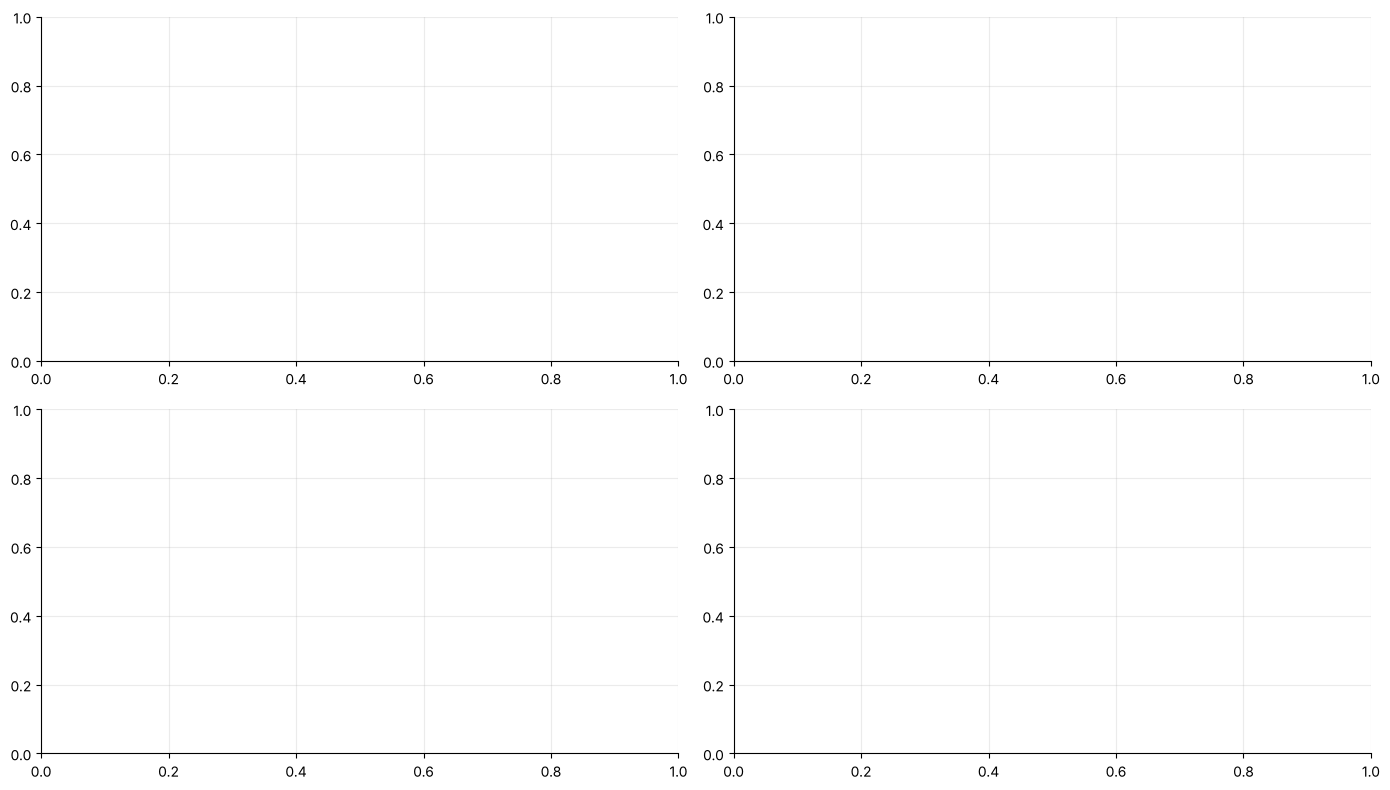

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
# 1a  YOUR CODE HERE (axes[0, 0])
# 1b  YOUR CODE HERE (axes[0, 1])
# 1c  YOUR CODE HERE (axes[1, 0])
# 1d  YOUR CODE HERE (axes[1, 1])
plt.tight_layout(); plt.show()

✍️ **Your three observations** (double-click to edit):
1. …
2. …
3. …

## Step 2 · Trend and seasonality analysis

Quantify what you saw. Tasks:

1. **STL decomposition** of the *log* price (`period=52`, `robust=True`). Compute the **seasonal strength** and **trend strength** (Lesson 1 formula).
2. Which calendar **months** are above/below trend (in %)? Put the answer in `peak_month` (most expensive) and `trough_month` (cheapest).
3. **Stationarity:** run ADF and KPSS on (i) the price, (ii) log price, (iii) weekly log change, (iv) 52-week seasonal difference of the log price.
4. Plot **ACF and PACF** of the weekly log change. Decide: how many regular differences *d* will your ARIMA need? Store it in `d_needed`.

<details><summary>💡 Hint 1</summary>

`stl = STL(np.log(y), period=52, robust=True).fit()` → `stl.seasonal`, `stl.trend`, `stl.resid`.

</details>

<details><summary>💡 Hint 2</summary>

Strength: `max(0, 1 - resid.var() / (seasonal + resid).var())`; for trend replace seasonal by trend.

</details>

<details><summary>💡 Hint 3</summary>

Month profile: `(np.exp(stl.seasonal).groupby(stl.seasonal.index.month).mean() - 1) * 100`; `idxmax()` / `idxmin()`.

</details>

<details><summary>💡 Hint 4</summary>

ADF/KPSS: `from statsmodels.tsa.stattools import adfuller, kpss`; remember the opposite null hypotheses. Wrap `kpss` in `warnings.catch_warnings()`.

</details>

In [4]:
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

peak_month, trough_month, d_needed = None, None, None
# 2.1 decomposition + strengths           YOUR CODE HERE
# 2.2 month profile                       YOUR CODE HERE
# 2.3 ADF / KPSS table                    YOUR CODE HERE
# 2.4 ACF / PACF of weekly log change     YOUR CODE HERE
print("peak month:", peak_month, "| trough month:", trough_month, "| d needed:", d_needed)

peak month: None | trough month: None | d needed: None


✍️ **Your conclusions:** how strong is the seasonality? Which differencing will you use and why?

## Step 3 · Moving-average baseline (and friends)

Before anything fancy, set the **bar to beat**. Using `walk_forward(y, forecaster, initial=INITIAL, horizon=8, step=STEP)`:

1. `wf_naive`: repeat the last value (`fc_naive`) → `record("naive", wf_naive)`
2. `wf_snaive`: repeat last year (`fc_snaive`)  → `record("seasonal naive", wf_snaive)`
3. `wf_ma`: moving average of **your chosen window** (`fc_ma(train, h, w)`) → `record("moving average", wf_ma)`.
   Try windows 2, 4, 8, 13 on the first few origins (or all of them) and pick one **using the data, not intuition**.

**Question:** which baseline is hardest to beat at h = 1? at h = 8? why?

<details><summary>💡 Hint 1</summary>

`walk_forward(y, fc_naive, initial=INITIAL, horizon=8, step=STEP)` returns a table for h = 1…8; `record` keeps h ∈ {1, 4, 8}.

</details>

<details><summary>💡 Hint 2</summary>

A window loop: `for w in (2, 4, 8, 13): wf = walk_forward(y, lambda tr, h, w=w: fc_ma(tr, h, w), ...)` and compare `mae(wf.actual, wf.forecast)`.

</details>

<details><summary>💡 Hint 3</summary>

Remember the closure trap: write `w=w` in the lambda.

</details>

In [5]:
wf_naive, wf_snaive, wf_ma = None, None, None
# YOUR CODE HERE

if wf_naive is not None:  record("naive", wf_naive)
if wf_snaive is not None: record("seasonal naive", wf_snaive)
if wf_ma is not None:     record("moving average", wf_ma)

✍️ **Your answer:** which baseline is toughest at h = 1, and at h = 8?

## Step 4 · ARIMA or SARIMA(X)

Build a statistical forecaster on **log price** (Lesson 5):

1. Choose the ARMA orders: fit `ARIMA(p, 1, q)` for p, q ∈ {0, 1} on the log price and pick the lowest AIC (store in `best_order`).
2. Use the helper `sarimax_forecaster(df, cols, order)` to create forecasters for **three** model variants and record each:
   - `"ARIMA"`: no exogenous columns
   - `"ARIMAX + Fourier"`: the six Fourier columns `sin1…cos3`
   - `"ARIMAX + Fourier + drivers"`: Fourier + `rain6_l8`, `fuel_l8`, `fest`
3. **Diagnose** the third model on the full sample: Ljung–Box test on the residuals; inspect the estimated coefficients (do their signs make sense?).

> ⚠️ Weekly SARIMA with m = 52 is impractical (Lesson 5); Fourier terms *are* the seasonal part. (**Bonus challenge:** resample to monthly and fit a true SARIMA(p,d,q)(P,D,Q)₁₂.)

<details><summary>💡 Hint 1</summary>

`from statsmodels.tsa.arima.model import ARIMA` ; `ARIMA(np.log(y), order=(p, 1, q)).fit().aic`.

</details>

<details><summary>💡 Hint 2</summary>

`cols_f = ['sin1','cos1','sin2','cos2','sin3','cos3']`; `f = sarimax_forecaster(df, cols_f, order=best_order)`; `walk_forward(y, f, initial=INITIAL, horizon=8, step=STEP)`.

</details>

<details><summary>💡 Hint 3</summary>

Each ARIMAX walk-forward takes ~5–15 seconds. For diagnostics: `SARIMAX(...).fit()`, `res.resid`, `acorr_ljungbox(res.resid[1:], lags=[10, 26])`, `res.params`.

</details>

In [6]:
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox

best_order = None
wf_arima = wf_arimax_f = wf_arimax_all = None
# 4.1 order selection by AIC          YOUR CODE HERE
# 4.2 three walk-forward evaluations  YOUR CODE HERE
# 4.3 diagnostics                     YOUR CODE HERE

if wf_arima is not None:      record("ARIMA", wf_arima)
if wf_arimax_f is not None:   record("ARIMAX + Fourier", wf_arimax_f)
if wf_arimax_all is not None: record("ARIMAX + Fourier + drivers", wf_arimax_all)

✍️ **Your answer:** did seasonality help? did the drivers? do the coefficient signs agree with agronomy?

## Step 5 · Regression with lag features

Time to treat forecasting as supervised learning (Lesson 6). Use `walk_forward_ml(df, model_factory, horizons=HORIZONS, initial=INITIAL, step=STEP)`:

1. Build a **Ridge regression** pipeline: `make_pipeline(StandardScaler(), Ridge(alpha=10))`. Record as `"Ridge (lag features)"`.
2. **Ablation:** repeat *without* the driver features (`use_drivers=False`) and record as `"Ridge (no drivers)"`. What do the drivers contribute?
3. Fit one Ridge on all data for h = 4 (`make_ml_table(df, 4)`), print the **largest coefficients** (standardised features): what is the model relying on?

> ⚠️ Remember: the table's target is the **h-step log return**; `walk_forward_ml` converts back to prices for you.

<details><summary>💡 Hint 1</summary>

`from sklearn.linear_model import Ridge; from sklearn.pipeline import make_pipeline; from sklearn.preprocessing import StandardScaler`.

</details>

<details><summary>💡 Hint 2</summary>

`walk_forward_ml(df, lambda: make_pipeline(StandardScaler(), Ridge(alpha=10)), horizons=HORIZONS, initial=INITIAL, step=STEP, use_drivers=False)`: extra keyword arguments go to `make_ml_table`.

</details>

<details><summary>💡 Hint 3</summary>

Coefficients: fit on `Xd = X.dropna()`, then `pipe[-1].coef_` aligned with `X.columns`; sort by absolute value.

</details>

In [7]:
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

wf_ridge = wf_ridge_nd = None
# 5.1 / 5.2 YOUR CODE HERE
# 5.3 coefficients YOUR CODE HERE

if wf_ridge is not None:    record("Ridge (lag features)", wf_ridge)
if wf_ridge_nd is not None: record("Ridge (no drivers)", wf_ridge_nd)

✍️ **Your answer:** what do the drivers contribute? Which features dominate?

## Step 6 · Random Forest

Now a non-linear learner. Record `"Random Forest"` using
`RandomForestRegressor(200, min_samples_leaf=5, max_features=0.5, random_state=0, n_jobs=1)` and `walk_forward_ml`.

**Think first:** why do we feed the forest *returns* rather than prices? (Hint: Lesson 6, §2.) Then look at **permutation importance** on a chronological hold-out (train on the first 80 % of rows for h = 4, test on the last 20 %).

<details><summary>💡 Hint 1</summary>

Wrap the constructor in a lambda: `lambda: RandomForestRegressor(200, min_samples_leaf=5, max_features=0.5, random_state=0, n_jobs=1)`.

</details>

<details><summary>💡 Hint 2</summary>

`from sklearn.inspection import permutation_importance`; `permutation_importance(model, Xte, yte, n_repeats=10, random_state=0, scoring='neg_mean_absolute_error')`.

</details>

<details><summary>💡 Hint 3</summary>

This cell takes ~20 s.

</details>

In [8]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance

wf_rf = None
# 6.1 walk-forward         YOUR CODE HERE
# 6.2 permutation importance YOUR CODE HERE

if wf_rf is not None: record("Random Forest", wf_rf)

✍️ **Your answer:** why returns instead of prices? which features matter most?

## Step 7 · XGBoost

Record `"XGBoost"` with `XGBRegressor(n_estimators=300, max_depth=3, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, random_state=0, n_jobs=1)`.

Then **tune honestly**: for h = 4 run a small `GridSearchCV` over `max_depth ∈ {2, 3, 4}` and `learning_rate ∈ {0.03, 0.1}` with `TimeSeriesSplit(n_splits=4, gap=3)`, using only the rows **before the last 52 weeks**. Compare the tuned and default models on the last 52 weeks (price MAE), and say whether tuning was worth it.

<details><summary>💡 Hint 1</summary>

Same pattern as Step 6 with `XGBRegressor`.

</details>

<details><summary>💡 Hint 2</summary>

Tuning recipe: Lesson 6 §6. Training rows: `d.iloc[:-52]`; hold-out: `d.iloc[-52:]`; price forecast = `df['price'].shift(4) * np.exp(pred)`.

</details>

<details><summary>💡 Hint 3</summary>

A tuned model that is *not* better on the hold-out is a perfectly valid, honest finding.

</details>

In [9]:
from xgboost import XGBRegressor
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit

wf_xgb = None
# 7.1 walk-forward           YOUR CODE HERE
# 7.2 time-aware tuning      YOUR CODE HERE

if wf_xgb is not None: record("XGBoost", wf_xgb)

✍️ **Your answer:** was tuning worth it?

## Step 8 · Model comparison and recommendation

The moment of truth. Everything you recorded is compared **on identical origins, horizons and metrics**.

1. Display `scoreboard(results)`.
2. Plot **MAE by horizon** for all models.
3. Compute each model's **win rate vs naive at h = 8**: the share of forecast origins where its absolute error was smaller than the naive forecast's. A model with lower MAE but a win rate near 50 % wins on a few big moves; a high win rate means *consistent* improvement.
4. Pick the model you would deploy and write a short **recommendation** (template below): best model, evidence, limitations, and the next experiment you'd run.

<details><summary>💡 Hint 1</summary>

Win rate: merge each model's table with the naive table on `(origin, h)` and compare `abs(actual - forecast)`.

</details>

<details><summary>💡 Hint 2</summary>

`results['naive']` must exist for skill and win-rate: it comes from Step 3.

</details>

<details><summary>💡 Hint 3</summary>

Don't over-interpret small differences: with ~19 origins, MAE gaps of a few percent are within noise.

</details>

In [10]:
board = scoreboard(results)
display(board)

# 8.2 MAE by horizon plot            YOUR CODE HERE
# 8.3 win rate vs naive at h = 8     YOUR CODE HERE

No results recorded yet: complete Steps 3-7 first.


None

### ✍️ Your recommendation (template)

**Best model & why:**

**Evidence** (numbers from the scoreboard; skill vs naive; consistency/win rate):

**Where does it fail?** (horizons, seasons, shocks such as droughts):

**Limitations** (simulated data, only 19 origins, retraining, exogenous inputs needed in advance):

**Next experiment I would run:**

## 🎓 Submission checklist
- [ ] All eight steps run top-to-bottom without errors.
- [ ] `scoreboard(results)` lists **at least**: naive, seasonal naive, moving average, one ARIMA-family model, Ridge, Random Forest, XGBoost.
- [ ] You wrote the observations/answers in the ✍️ cells.
- [ ] You can explain, for each model, **how leakage was avoided**.
- [ ] You wrote the final recommendation.

### 🚀 Stretch goals
1. Repeat for **tomato, onion and rice**. Does the same model win? Which crop is hardest to forecast and why?
2. Add a **deep-learning** model (`walk_forward_dl`, Lesson 7) and a **3-seed ensemble**.
3. Build a **simple ensemble** (average of ARIMAX + XGBoost forecasts). Ensembles of diverse models often beat every member.
4. Add **prediction intervals** (e.g., from the empirical walk-forward errors) and check their coverage.
5. Then move on to the **capstone project** in `project/`.